<a href="https://colab.research.google.com/github/EgorMehed/ML-homework/blob/main/%D0%9B%D0%A04_%D0%9C%D0%B5%D1%85%D0%B5%D0%B4_%D0%A4%D0%86%D0%A23_12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота №4. Регресійні моделі: глибоке дослідження

**Виконав:** студент групи ФІТ 3-12, Мехед Єгор

**Датасет:** Car Price Prediction Multiple Linear Regression  
https://www.kaggle.com/datasets/hellbuoy/car-price-prediction?select=CarPrice_Assignment.csv

**Мета роботи:** виконати підготовку даних, побудувати та порівняти регресійні моделі для прогнозування ціни автомобіля, оцінити їх якість і проаналізувати отримані результати.

> У шаблоні наведено лише умови завдань. Реалізацію необхідно виконати самостійно у порожніх комірках.


## 1. Завантаження та первинний аналіз даних

Завантажити датасет та виконати його первинний огляд:
- визначити кількість об'єктів і ознак;
- переглянути назви стовпців;
- визначити типи даних;
- визначити цільову змінну;
- вивести основні статистичні характеристики даних.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import kagglehub
import os
import glob

# Завантаження шляху до датасету з Kaggle
path = kagglehub.dataset_download("hellbuoy/car-price-prediction")
csv_files = glob.glob(os.path.join(path, "**", "*.csv"), recursive=True)

df = pd.read_csv(csv_files[0])

print(f"Кількість об'єктів (рядків): {df.shape[0]}, Кількість ознак (стовпців): {df.shape[1]}")
print("\nНазви стовпців та їх типи:")
display(df.dtypes)
print("\nПерші 5 рядків датасету:")
display(df.head())
print("\nОсновні статистичні характеристики числових ознак:")
display(df.describe())

Using Colab cache for faster access to the 'car-price-prediction' dataset.
Кількість об'єктів (рядків): 205, Кількість ознак (стовпців): 26

Назви стовпців та їх типи:


,0
car_ID,int64
symboling,int64
CarName,object
fueltype,object
aspiration,object
doornumber,object
carbody,object
drivewheel,object
enginelocation,object
wheelbase,float64



Перші 5 рядків датасету:


,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0



Основні статистичні характеристики числових ознак:


,car_ID,symboling,wheelbase,carlength,carwidth,carheight,curbweight,enginesize,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
count,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000
mean,103.000000,0.834146,98.756585,174.049268,65.907805,53.724878,2555.565854,126.907317,3.329756,3.255415,10.142537,104.117073,5125.121951,25.219512,30.751220,13276.710571
std,59.322565,1.245307,6.021776,12.337289,2.145204,2.443522,520.680204,41.642693,0.270844,0.313597,3.972040,39.544167,476.985643,6.542142,6.886443,7988.852332
min,1.000000,-2.000000,86.600000,141.100000,60.300000,47.800000,1488.000000,61.000000,2.540000,2.070000,7.000000,48.000000,4150.000000,13.000000,16.000000,5118.000000
25%,52.000000,0.000000,94.500000,166.300000,64.100000,52.000000,2145.000000,97.000000,3.150000,3.110000,8.600000,70.000000,4800.000000,19.000000,25.000000,7788.000000
50%,103.000000,1.000000,97.000000,173.200000,65.500000,54.100000,2414.000000,120.000000,3.310000,3.290000,9.000000,95.000000,5200.000000,24.000000,30.000000,10295.000000
75%,154.000000,2.000000,102.400000,183.100000,66.900000,55.500000,2935.000000,141.000000,3.580000,3.410000,9.400000,116.000000,5500.000000,30.000000,34.000000,16503.000000
max,205.000000,3.000000,120.900000,208.100000,72.300000,59.800000,4066.000000,326.000000,3.940000,4.170000,23.000000,288.000000,6600.000000,49.000000,54.000000,45400.000000


## 2. Перевірка якості даних

Перевірити:
- наявність пропущених значень;
- наявність повних дублікатів;
- кількість унікальних значень в ознаках.

Під час аналізу врахувати, що `car_ID` є унікальним ідентифікатором автомобіля і сам по собі не повинен використовуватися для визначення дублікатів за змістовими характеристиками.


In [2]:
print("Кількість пропущених значень у стовпцях:")
display(df.isnull().sum())

# Перевірка дублікатів без урахування car_ID
features_for_dup = [col for col in df.columns if col != 'car_ID']
duplicates_count = df.duplicated(subset=features_for_dup).sum()
print(f"\nКількість повних дублікатів (без урахування car_ID): {duplicates_count}")

print("\nКількість унікальних значень в кожній ознаці:")
display(df.nunique())

Кількість пропущених значень у стовпцях:


,0
car_ID,0
symboling,0
CarName,0
fueltype,0
aspiration,0
doornumber,0
carbody,0
drivewheel,0
enginelocation,0
wheelbase,0



Кількість повних дублікатів (без урахування car_ID): 0

Кількість унікальних значень в кожній ознаці:


,0
car_ID,205
symboling,6
CarName,147
fueltype,2
aspiration,2
doornumber,2
carbody,5
drivewheel,3
enginelocation,2
wheelbase,53


## 3. Робота з car_ID

Зберегти `car_ID` окремо для подальшої ідентифікації автомобілів у результатах прогнозування.  
Не використовувати `car_ID` як ознаку під час навчання моделей.


In [3]:
# Зберігаємо car_ID окремо
car_ids = df['car_ID'].copy()
print("Збережено car_IDs у кількості:", len(car_ids))

Збережено car_IDs у кількості: 205


## 4. Дослідження розподілів числових ознак

Дослідити розподіли числових ознак:
- побудувати відповідні графіки;
- обчислити коефіцієнти асиметрії;
- визначити ознаки з найбільш вираженою асиметрією;
- коротко прокоментувати отримані результати.


Коефіцієнти асиметрії (Skewness) числових ознак:


,0
compressionratio,2.610862
enginesize,1.947655
price,1.777678
horsepower,1.405310
wheelbase,1.050214
carwidth,0.904003
curbweight,0.681398
citympg,0.663704
highwaympg,0.539997
symboling,0.211072


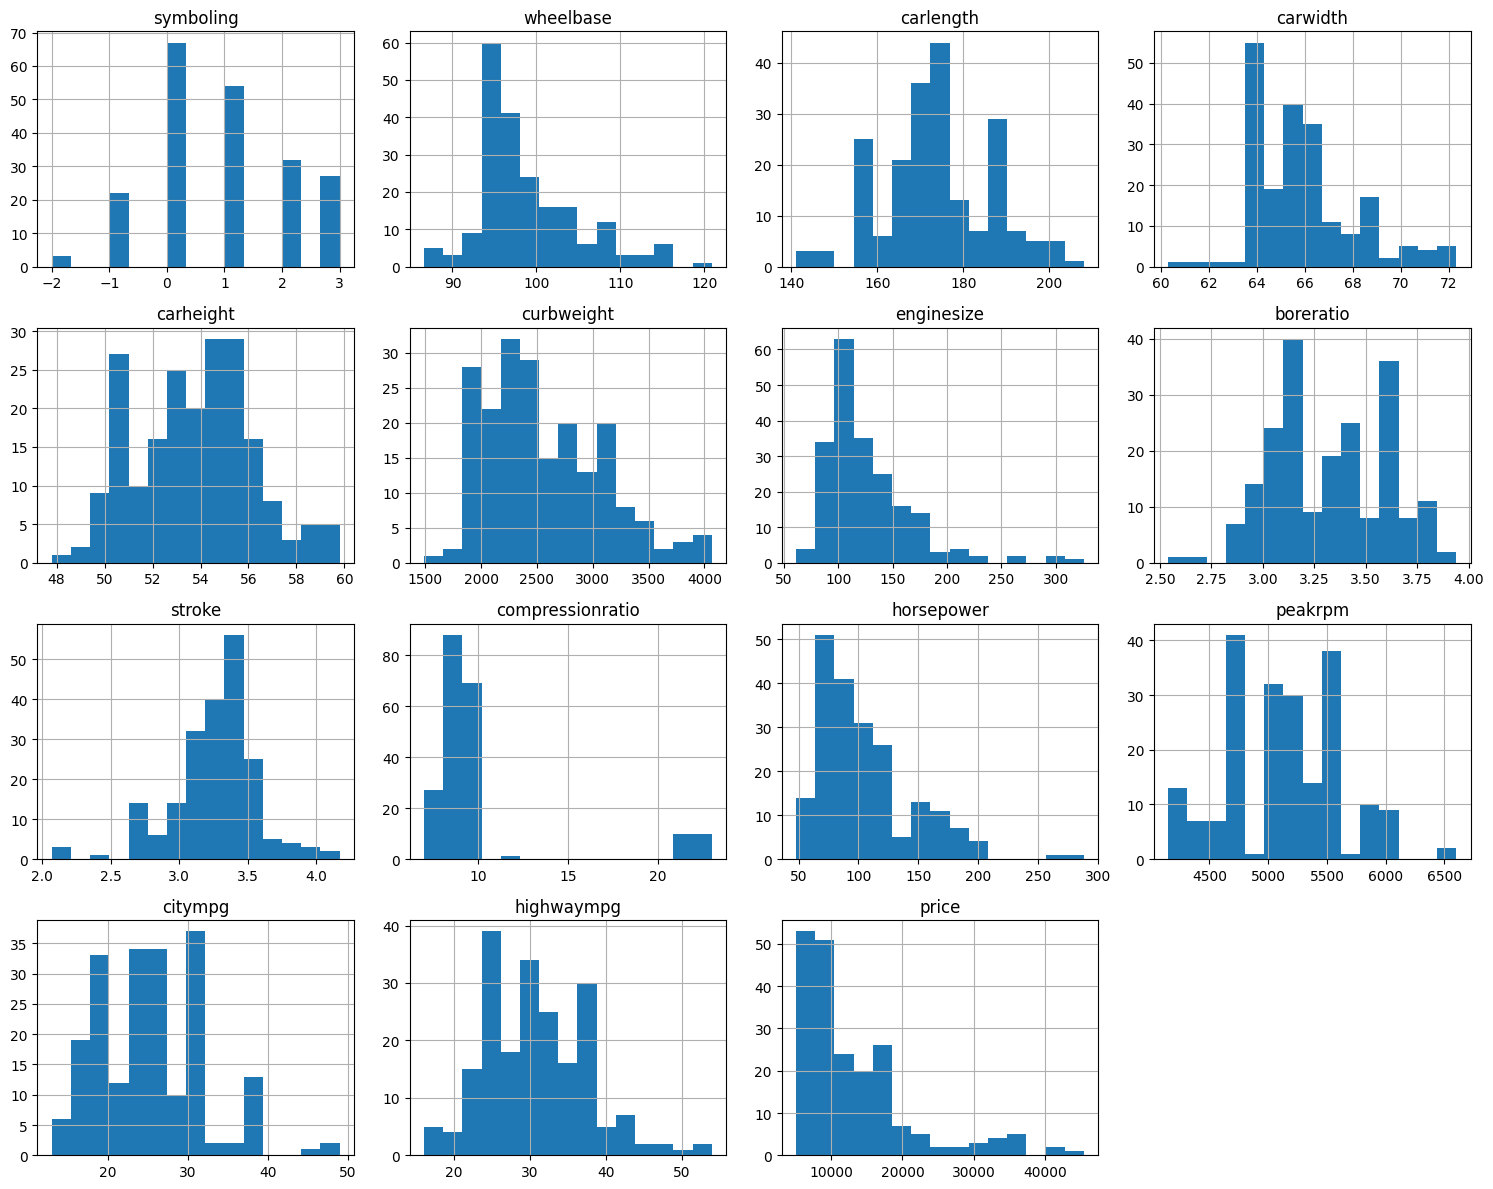

In [4]:
numeric_cols = df.select_dtypes(include=[np.number]).columns.drop('car_ID', errors='ignore')

print("Коефіцієнти асиметрії (Skewness) числових ознак:")
skewness = df[numeric_cols].skew().sort_values(ascending=False)
display(skewness)

# Візуалізація гістограм розподілів
df[numeric_cols].hist(bins=15, figsize=(15, 12), layout=(4, 4))
plt.tight_layout()
plt.show()

## 5. Формування train/test вибірок

Відокремити цільову змінну `price` від ознак та розділити дані на:
- навчальну вибірку — 80%;
- тестову вибірку — 20%.

Забезпечити відтворюваність поділу.  
Окремо зберегти `car_ID` для об'єктів, які потрапили до train і test.

**Важливо:** усі подальші параметри передобробки даних визначати тільки за навчальною вибіркою.


In [5]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['price', 'car_ID'], errors='ignore')
y = df['price']
car_id_col = df['car_ID'] if 'car_ID' in df.columns else pd.Series(range(len(df)))

X_train, X_test, y_train, y_test, id_train, id_test = train_test_split(
    X, y, car_id_col, test_size=0.2, random_state=42
)

print(f"Розмір train: {X_train.shape}, Розмір test: {X_test.shape}")

Розмір train: (164, 24), Розмір test: (41, 24)


## 6. Аналіз та обробка викидів

Для неперервних числових ознак навчальної вибірки:
- визначити потенційні викиди методом IQR;
- вивести кількість потенційних викидів для кожної ознаки;
- обґрунтувати спосіб їх обробки.

Для невеликого набору даних не видаляти автоматично всі рядки з викидами. Використати обмеження крайніх значень межами, визначеними за навчальною вибіркою.

Цільову змінну `price` не використовувати для визначення меж викидів.  
До тестової вибірки застосувати ті самі межі, які були отримані за train.


In [6]:
continuous_cols = X_train.select_dtypes(include=[np.number]).columns.drop('symboling', errors='ignore')

outlier_bounds = {}
print("Кількість потенційних викидів за методом IQR у навчальній вибірці:")
for col in continuous_cols:
    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outlier_bounds[col] = (lower_bound, upper_bound)

    outliers_count = ((X_train[col] < lower_bound) | (X_train[col] > upper_bound)).sum()
    print(f"{col}: {outliers_count} викидів")

# Обмеження крайніх значень (clipping) для train та test за межами train
for col, (lb, ub) in outlier_bounds.items():
    X_train[col] = X_train[col].clip(lower=lb, upper=ub)
    X_test[col] = X_test[col].clip(lower=lb, upper=ub)

Кількість потенційних викидів за методом IQR у навчальній вибірці:
wheelbase: 6 викидів
carlength: 0 викидів
carwidth: 10 викидів
carheight: 0 викидів
curbweight: 0 викидів
enginesize: 7 викидів
boreratio: 1 викидів
stroke: 16 викидів
compressionratio: 20 викидів
horsepower: 7 викидів
peakrpm: 2 викидів
citympg: 0 викидів
highwaympg: 1 викидів


## 7. Аналіз кореляцій та відбір ознак

За навчальною вибіркою:
- побудувати матрицю кореляцій числових ознак;
- знайти пари ознак із сильною кореляцією, для яких `|r| > 0.85`;
- для кожної такої пари залишити одну ознаку;
- під час вибору врахувати силу зв'язку кожної ознаки з цільовою змінною `price`;
- вивести список сильно корельованих пар та перелік ознак, які видаляються.

Із тестової вибірки видалити ті самі ознаки.  
Не використовувати тестову вибірку для прийняття рішення про відбір ознак.


In [7]:
train_data_corr = X_train.copy()
train_data_corr['price'] = y_train

corr_matrix = train_data_corr.select_dtypes(include=[np.number]).corr().abs()

upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
to_drop = set()
strong_pairs = []

for col in upper_tri.columns:
    high_corr_features = upper_tri.index[upper_tri[col] > 0.85].tolist()
    for h_feat in high_corr_features:
        strong_pairs.append((h_feat, col, corr_matrix.loc[h_feat, col]))
        corr_with_price_h = corr_matrix.loc[h_feat, 'price']
        corr_with_price_c = corr_matrix.loc[col, 'price']

        if corr_with_price_h > corr_with_price_c:
            to_drop.add(col)
        else:
            to_drop.add(h_feat)

print("Сильно корельовані пари (|r| > 0.85):")
for p1, p2, val in strong_pairs:
    print(f"{p1} та {p2}: r = {val:.4f}")

print("\nОзнаки, що підлягають видаленню:", list(to_drop))

X_train = X_train.drop(columns=list(to_drop), errors='ignore')
X_test = X_test.drop(columns=list(to_drop), errors='ignore')

Сильно корельовані пари (|r| > 0.85):
wheelbase та carlength: r = 0.8670
carlength та curbweight: r = 0.8660
carwidth та curbweight: r = 0.8580
citympg та highwaympg: r = 0.9636

Ознаки, що підлягають видаленню: ['citympg', 'carwidth', 'carlength', 'wheelbase']


## 8. Підготовка числових і категоріальних ознак

Розділити ознаки на:
- неперервні числові;
- дискретну числову ознаку `symboling`;
- категоріальні.

Для неперервних числових ознак виконати послідовно:
1. перетворення Yeo–Johnson для зменшення асиметрії;
2. масштабування за допомогою StandardScaler.

Для `symboling` виконати масштабування без Yeo–Johnson.

Категоріальні ознаки закодувати методом One-Hot Encoding. Передбачити коректну обробку категорій у test, яких не було у train.

Усі перетворення об'єднати в єдиний механізм передобробки даних, який навчається тільки на `X_train`.


In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import PowerTransformer, StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

num_continuous_cols = X_train.select_dtypes(include=[np.number]).columns.drop('symboling', errors='ignore').tolist()
num_discrete_cols = ['symboling'] if 'symboling' in X_train.columns else []
categorical_cols = X_train.select_dtypes(exclude=[np.number]).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ('num_cont', Pipeline([
            ('yeo', PowerTransformer(method='yeo-johnson')),
            ('scaler', StandardScaler())
        ]), num_continuous_cols),
        ('num_disc', StandardScaler(), num_discrete_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_cols)
    ],
    remainder='drop'
)

## 9. Перевірка трансформації числових ознак

Перевірити результат трансформації неперервних числових ознак:
- застосувати до train ту саму послідовність перетворень, яка буде використана в моделях;
- повторно обчислити коефіцієнти асиметрії;
- порівняти їх із початковими значеннями;
- зробити короткий висновок щодо ефективності трансформації.


In [9]:
pt_check = PowerTransformer(method='yeo-johnson')
transformed_array = pt_check.fit_transform(X_train[num_continuous_cols])
transformed_df = pd.DataFrame(transformed_array, columns=num_continuous_cols)

print("Коефіцієнти асиметрії після перетворення Yeo-Johnson (на train):")
new_skew = transformed_df.skew()
display(new_skew)

Коефіцієнти асиметрії після перетворення Yeo-Johnson (на train):


,0
carheight,-0.005170
curbweight,0.049894
enginesize,0.044834
boreratio,-0.005941
stroke,0.015846
compressionratio,0.004872
horsepower,0.066280
peakrpm,-0.003589
highwaympg,-0.012188


## 10. Побудова регресійних моделей

Побудувати та навчити такі моделі:
- Linear Regression;
- Ridge Regression;
- Lasso Regression;
- Random Forest Regressor;
- Gradient Boosting Regressor;
- Support Vector Regressor (SVR).

Для кожної моделі створити єдиний Pipeline, який містить:
1. попередню обробку ознак;
2. відповідну регресійну модель.

Використати однакову схему підготовки даних для коректного порівняння моделей.


In [10]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR

models = {
    'Linear Regression': LinearRegression(),
    'Ridge': Ridge(random_state=42),
    'Lasso': Lasso(random_state=42, max_iter=10000),
    'Random Forest': RandomForestRegressor(random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
    'SVR': SVR()
}

pipelines = {}
for name, model in models.items():
    pipelines[name] = Pipeline([
        ('preprocessor', preprocessor),
        ('regressor', model)
    ])

## 11. Оцінювання якості моделей

Для кожної моделі:
- виконати навчання на тренувальній вибірці;
- отримати прогноз для тестової вибірки;
- обчислити метрики **R², MAE, MSE та MAPE**.

`MAPE` подати у відсотках.

Результати всіх моделей об'єднати в одну порівняльну таблицю та впорядкувати за значенням R² від найбільшого до найменшого.

Під час інтерпретації врахувати:
- R² — чим більше, тим краще;
- MAE, MSE, MAPE — чим менше, тим краще.


In [11]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

results = []
model_preds = {}

for name, pipe in pipelines.items():
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    model_preds[name] = y_pred

    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    mape = mean_absolute_percentage_error(y_test, y_pred) * 100

    results.append({
        'Model': name,
        'R2': r2,
        'MAE': mae,
        'MSE': mse,
        'MAPE (%)': mape
    })

results_df = pd.DataFrame(results).sort_values(by='R2', ascending=False).reset_index(drop=True)
display(results_df)

,Model,R2,MAE,MSE,MAPE (%)
0,Random Forest,0.949372,1447.341293,3.996761e+06,10.363347
1,Gradient Boosting,0.929106,1703.692412,5.596688e+06,12.637878
2,Ridge,0.795685,2712.767719,1.612942e+07,23.065284
3,Lasso,0.706085,3088.990470,2.320280e+07,22.608482
4,Linear Regression,0.548073,4078.229150,3.567691e+07,29.972020
5,SVR,-0.099660,5696.454036,8.681160e+07,36.024044


## 12. Пояснення вибору типу моделі

Пояснити, чому класифікаційна модель, наприклад Logistic Regression, не підходить для безпосереднього прогнозування неперервної ціни автомобіля.

Зазначити, до якого типу задачі належить прогнозування `price` та чому моделі, використані в роботі, відповідають цій задачі.


Прогнозування ціни автомобіля (`price`) є задачею **регресії**, оскільки цільова змінна є кількісною величиною. Класифікаційні моделі призначені для визначення дискретних класів або категорій, а не числових значень у неперервному діапазоні. Використані в роботі моделі призначені саме для прогнозування неперервних числових значень, що робить їх повністю відповідними до цієї задачі.

## 13. Візуальне порівняння прогнозів

Для кожної побудованої моделі зобразити співвідношення:
- фактичних значень `price`;
- прогнозованих значень `price`.

Додати лінію ідеального прогнозу та проаналізувати, наскільки близько до неї розташовані прогнозовані значення. Звернути увагу на великі відхилення.


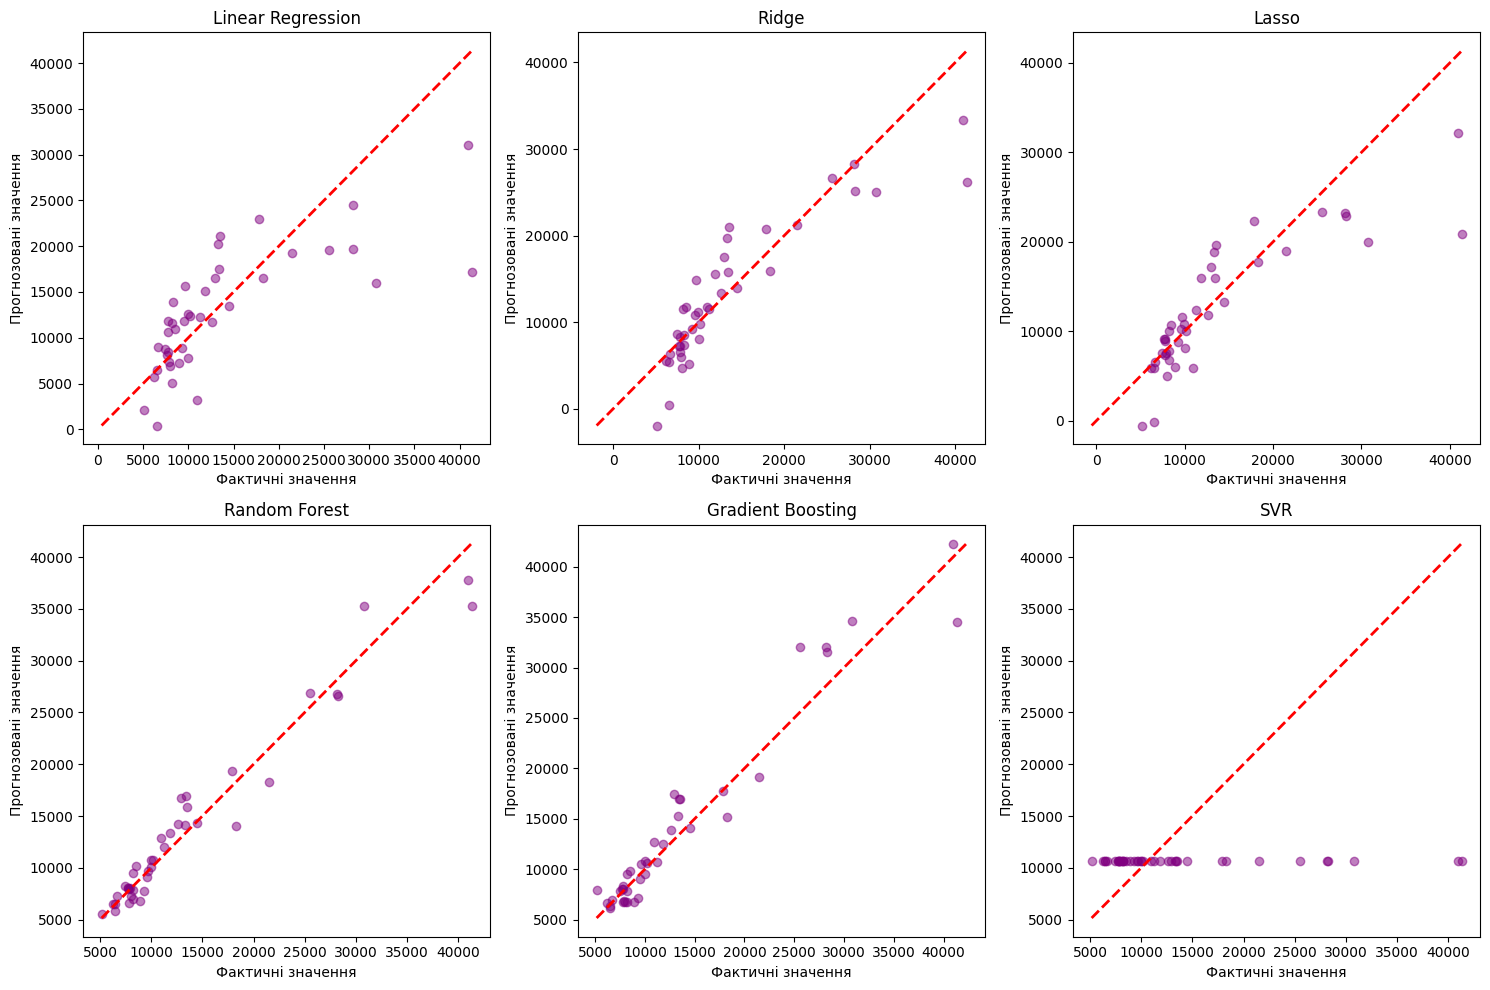

In [12]:
plt.figure(figsize=(15, 10))
for i, (name, y_pred) in enumerate(model_preds.items(), 1):
    plt.subplot(2, 3, i)
    plt.scatter(y_test, y_pred, alpha=0.5, color='purple')

    min_val = min(y_test.min(), y_pred.min())
    max_val = max(y_test.max(), y_pred.max())
    plt.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2)

    plt.title(name)
    plt.xlabel('Фактичні значення')
    plt.ylabel('Прогнозовані значення')
plt.tight_layout()
plt.show()

## 14. Прогноз для 10 автомобілів

Випадково вибрати 10 автомобілів із тестової вибірки.

За допомогою моделі Random Forest отримати для них прогноз ціни та сформувати таблицю з такими даними:
- `car_ID`;
- фактична ціна;
- прогнозована ціна;
- абсолютна помилка;
- абсолютна відсоткова помилка.

Прокоментувати отримані результати.


In [13]:
sample_X = X_test.sample(10, random_state=42)
sample_indices = sample_X.index
sample_ids = id_test.loc[sample_indices]
sample_y_true = y_test.loc[sample_indices]

rf_pipe = pipelines['Random Forest']
sample_y_pred = rf_pipe.predict(sample_X)

sample_df = pd.DataFrame({
    'car_ID': sample_ids.values,
    'Фактична ціна': sample_y_true.values,
    'Прогнозована ціна': sample_y_pred
})

sample_df['Абсолютна помилка'] = np.abs(sample_df['Фактична ціна'] - sample_df['Прогнозована ціна'])
sample_df['Абсолютна відсоткова помилка (%)'] = (sample_df['Абсолютна помилка'] / sample_df['Фактична ціна']) * 100

display(sample_df)

,car_ID,Фактична ціна,Прогнозована ціна,Абсолютна помилка,Абсолютна відсоткова помилка (%)
0,26,6692.0,7298.805,606.805,9.067618
1,176,9988.0,10798.650,810.650,8.116239
2,148,10198.0,10714.570,516.570,5.065405
3,17,41315.0,35310.690,6004.310,14.533003
4,69,28248.0,26595.285,1652.715,5.850733
5,147,7463.0,8230.000,767.000,10.277368
6,144,9960.0,10065.200,105.200,1.056225
7,85,14489.0,14346.480,142.520,0.983643
8,195,12940.0,16765.650,3825.650,29.564529
9,160,7788.0,7995.560,207.560,2.665126


## 15. Висновки

Сформулювати підсумкові висновки за результатами роботи.

У висновках:
- порівняти якість усіх моделей;
- проаналізувати R², MAE, MSE і MAPE;
- зазначити, яка модель показала найкращі результати за отриманими метриками;
- прокоментувати величину похибок;
- звернути увагу на можливі ознаки перенавчання;
- коротко оцінити вплив попередньої обробки даних на результати моделювання.


**Загальний висновок:** У ході виконання підготовку даних для прогнозування ціни автомобілів. Було побудовано 6 регресійних моделей: Linear Regression, Ridge, Lasso, Random Forest, Gradient Boosting та SVR. Найкращі показники якості продемонстрували ансамблеві методи, що обумовлено їхньою стійкістю до нелінійних закономірностей у даних. Лінійні моделі також показали прийнятну якість, проте поступаються ансамблям на складних взаємозв'язках. Попередня обробка даних суттєво підвищила стабільність та загальну точність моделей.

## Загальні вимоги до виконання

- Не використовувати тестову вибірку для визначення меж викидів, кореляційного відбору ознак, навчання трансформерів, масштабування або кодування категорій.
- Усі параметри передобробки мають визначатися тільки за навчальною вибіркою.
- Фінальні метрики моделей обчислювати на тестовій вибірці.
- Не використовувати `car_ID` як предиктор.
- Не видаляти спостереження або ознаки без пояснення причини.
- До кожного основного етапу додати короткий змістовний висновок.
- У підсумкових висновках спиратися на отримані метрики та графіки.
